<a href="https://colab.research.google.com/github/Huzaif005/Machine-Learning-External-/blob/main/practical_8_Assignment_on_Logistic_Regression_for_Binary_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##6: Logistic Regression for Binary Classification


**Aim**

To implement Logistic Regression on a binary classification dataset and evaluate the model using a Confusion Matrix, Precision, Recall, and F1-score.

Objectives
- Understand the working of Logistic Regression.
- Implement Logistic Regression for binary classification.
- Evaluate the model using classification metrics.
- Interpret the Confusion Matrix, Precision, Recall, and F1-score.

In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import matplotlib.pyplot as plt

In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Shape:", X.shape)
print("Target Classes:", data.target_names)

Dataset Shape: (569, 30)
Target Classes: ['malignant' 'benign']


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [4]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [5]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [6]:
y_pred = model.predict(X_test)

print("Actual Values:", y_test[:10])
print("Predicted Values:", y_pred[:10])

Actual Values: [0 1 0 1 0 1 1 0 0 0]
Predicted Values: [0 1 0 1 0 1 1 0 0 0]


Confusion Matrix:
[[41  1]
 [ 1 71]]


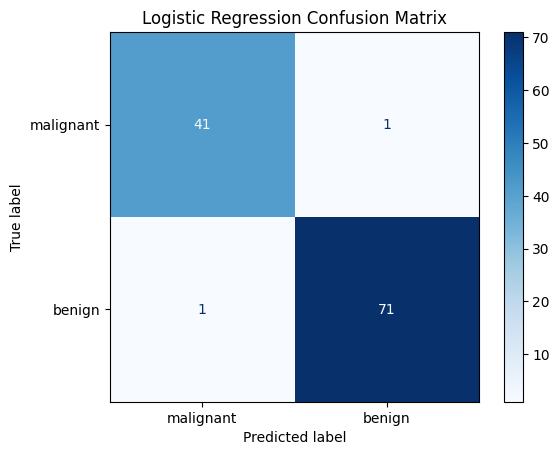

In [7]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

display.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [8]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

Precision: 0.9861
Recall: 0.9861
F1-score: 0.9861


In [9]:
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

